# MeSquare cardio digital twin: from raw NHANES to a personalized prediction

This notebook follows one path from the raw NHANES 2021-2023 files to a personalized
biomarker prediction and an AHA PREVENT risk score. Each step says what it does and why,
shows row counts before and after (and what was dropped), a small sample of the data,
and one plot or table with a one-line takeaway.

Everything runs through `src/`, the same code the API serves. You need `DATABASE_URL`
in `.env` (NHANES tables loaded by `upload_data.py`), a trained bundle
(`uv run python train_model.py`), the activation registry
(`uv run python evaluate_lab_stage.py`), and R with the official `AHAprevent` package.

| Step | Section |
|---|---|
| 1 | Load NHANES 2021-2023 |
| 2 | Explore |
| 3 | Clean and process |
| 4 | Feature engineering |
| 5 | Train the quantile prior |
| 6 | Evaluate the prior (goals 2-4) |
| 7 | Ingest a lab in the input format |
| 8 | Lab-anchored band (goals 1, 3, 5) |
| 8a-8d | Wearables: ingest, windows, residual gate, shadow mode |
| 9 | Risk score |
| 10 | End-to-end persona |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

In [2]:
import time
from datetime import date, timedelta

import matplotlib.pyplot as plt
import numpy as np
import orjson
import polars as pl
from fastapi.testclient import TestClient
from sqlalchemy import text
from tqdm.auto import tqdm

from config.settings import settings
from src.components.analytes import ANALYTES, MODEL_ANALYTES
from src.components.calibration import calibration_groups, subgroup_coverage
from src.components.data_transformation import NHANES_FILENAMES, TABLE_NAMES
from src.components.egfr import egfr_ckd_epi_2021
from src.components.feature_engineering import prepare_features
from src.components.model_artifact import QuantileModelBundle
from src.components.model_config import (
    FEATURES,
    LEARNING_RATE,
    N_SPLITS,
    PARAM_GRID,
    QUANTILES,
    TARGET_WEIGHTS,
)
from src.components.personalization.activation import load_registry
from src.components.personalization.lab_anchor import lab_sigma
from src.components.personalization.residual_model import (
    GATE_MIN_USERS,
    PairSet,
    gate_residual_model,
    train_residual_model,
)
from src.components.personalization.wearable_windows import (
    WEARABLE_METRICS,
    daily_values,
    feature_windows,
)
from src.components.prevent import package_version
from src.components.record_ingestion import ingest_records
from src.pipeline.evaluation_pipeline import grouped_split, holdout_predictions
from src.pipeline.prediction_pipeline import QuantilePredictor
from src.pipeline.training_pipeline import (
    design_clusters,
    load_training_frame,
    plausible_values,
    train_target,
)
from src.pipeline.twin_pipeline import TwinEngine, TwinRequest, twin_state
from src.repository.postgres_db_connection import NhanesRepository

plt.rcParams["figure.dpi"] = 110
FIXTURES = ROOT / "notebooks" / "fixtures"
UNITS = {name: ANALYTES[name].unit for name in MODEL_ANALYTES}
bundle = QuantileModelBundle.load_latest(settings.model_dir)
registry = load_registry()
engine = TwinEngine(
    prior=QuantilePredictor(bundle),
    registry=registry,
    prevent_version=package_version(),
)
print(f"prior: {bundle.version} | registry: {registry.version}")
print(f"PREVENT: {engine.prevent_version}")

/Users/khanhpham/Documents/KhanhWorld/MeSquare/MeSquareMLEngine/.claude/worktrees/cardio-digital-twin-personalization-bc7c43/.venv/lib/python3.15/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


prior: 20261104T1154Z | registry: activation-20261104T1154Z
PREVENT: AHAprevent 1.1.0


## 1. Load NHANES 2021-2023

**What and why.** The prior is learned from the CDC's NHANES August 2021-August 2023
cycle. `upload_data.py` loaded one database table per public `.xpt` file into the
`nhanes` schema. Every file shares one join key, `seqn` (respondent sequence number),
so a person's demographics, exam and lab results line up across files.

In [3]:
repository = NhanesRepository.from_settings(settings)
with repository.engine.connect() as connection:
    raw_counts = pl.DataFrame(
        [
            {
                "file": filename,
                "table": f"nhanes.{TABLE_NAMES[filename]}",
                "rows": connection.execute(
                    text(f"SELECT count(*) FROM nhanes.{TABLE_NAMES[filename]}")
                ).scalar_one(),
            }
            for filename in NHANES_FILENAMES
        ]
    )
    people = connection.execute(
        text("SELECT count(DISTINCT seqn) FROM nhanes.demographics")
    ).scalar_one()
print(
    f"{len(NHANES_FILENAMES)} files, join key: seqn. People in demographics: {people:,}"
)
raw_counts

10 files, join key: seqn. People in demographics: 11,933


file,table,rows
str,str,i64
"""BIOPRO_L.xpt""","""nhanes.biochemistry_profiles""",7199
"""BMX_L.xpt""","""nhanes.body_measures""",8860
"""BPQ_L.xpt""","""nhanes.blood_pressure_choleste…",8501
"""BPXO_L.xpt""","""nhanes.blood_pressure_readings""",7801
"""DEMO_L.xpt""","""nhanes.demographics""",11933
"""DIQ_L.xpt""","""nhanes.diabetes_questionnaires""",11744
"""GHB_L.xpt""","""nhanes.glycohemoglobin_results""",7199
"""HDL_L.xpt""","""nhanes.hdl_cholesterol_results""",8068
"""SMQ_L.xpt""","""nhanes.smoking_questionnaires""",9015


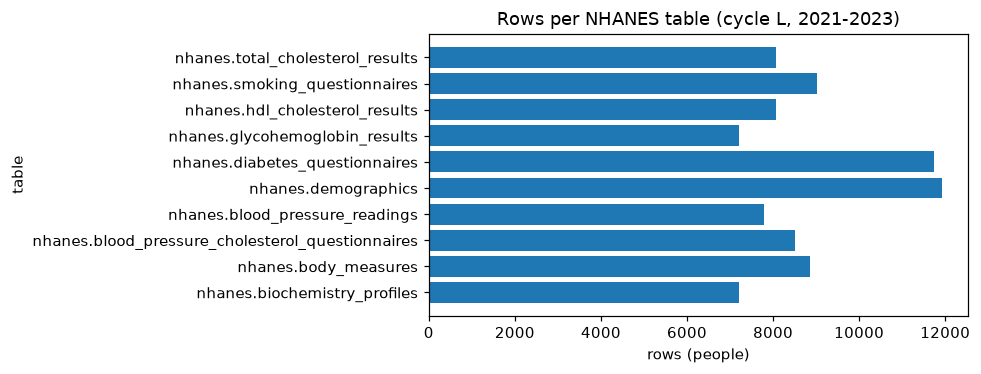

Takeaway: labs exist for 8,068 of 11,933 people, so lab targets cover a subsample with their own survey weight.


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.barh(raw_counts["table"].to_list(), raw_counts["rows"].to_list())
ax.set_title("Rows per NHANES table (cycle L, 2021-2023)")
ax.set_xlabel("rows (people)")
ax.set_ylabel("table")
fig.tight_layout()
plt.show()
lab_rows = raw_counts.filter(pl.col("table") == "nhanes.hdl_cholesterol_results")[
    "rows"
][0]
print(
    f"Takeaway: labs exist for {lab_rows:,} of {people:,} "
    "people, so lab targets cover a subsample with their "
    "own survey weight."
)

## 2. Explore

**What and why.** `ml.cardiovascular_training` (built by `sql/derived/`) joins the files
into one row per adult, with the five targets: non-HDL cholesterol, HDL cholesterol,
HbA1c, eGFR (computed here with CKD-EPI 2021) and systolic blood pressure. Before
modelling we look at the target distributions, what is missing, and the survey weights
that make the sample represent US adults.

In [5]:
frame = load_training_frame(settings)
print(f"Rows: {frame.height:,} adults")
frame.select(
    ["seqn", "sex", "age", "race_eth", *MODEL_ANALYTES, "wt_lab", "wt_mec"]
).head(5)

Rows: 5,681 adults


seqn,sex,age,race_eth,non_hdl,hdl,hba1c,egfr,sbp,wt_lab,wt_mec
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
130378.0,1.0,43.0,6.0,219.0,45.0,5.6,112.61418,132.67,56042.12941,54374.463898
130379.0,1.0,66.0,3.0,154.0,60.0,5.6,97.975999,117.0,37435.705647,34084.721548
130380.0,2.0,44.0,2.0,138.0,49.0,6.2,111.687296,109.0,85328.844519,81196.277992
130386.0,1.0,34.0,1.0,137.0,46.0,5.1,118.212538,115.0,44526.214135,39988.45294
130387.0,2.0,68.0,3.0,161.0,42.0,5.9,85.298556,141.33,22746.296353,20776.25485


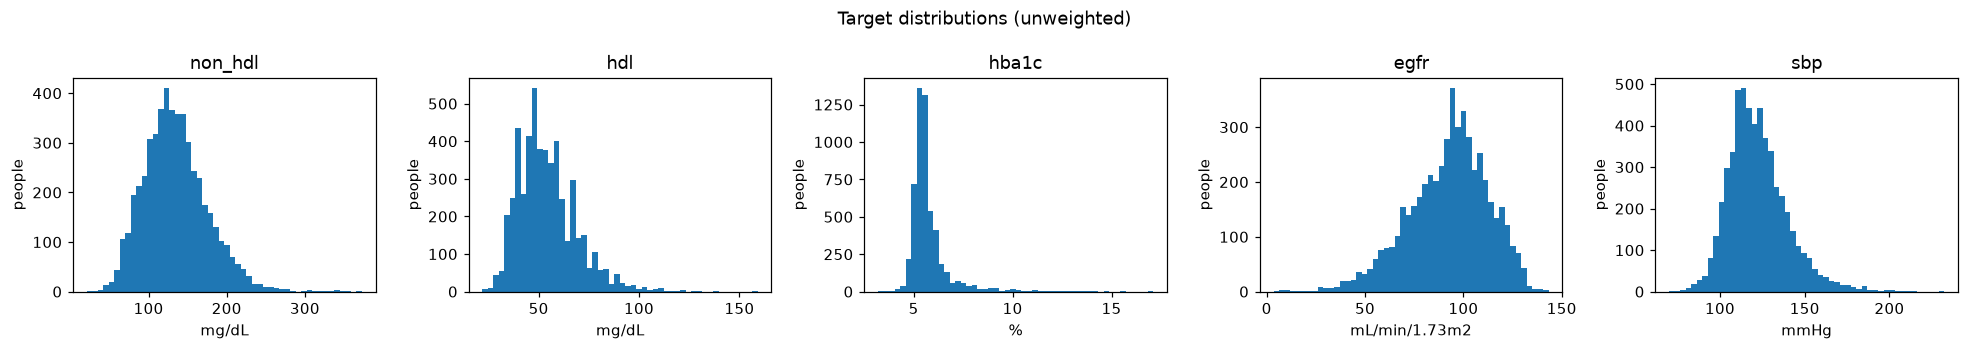

Takeaway: every target is right-skewed, which is why the twin works on the log scale.


In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, name in zip(axes, MODEL_ANALYTES, strict=True):
    values = frame[name].drop_nulls().to_numpy()
    ax.hist(values, bins=50)
    ax.set_title(name)
    ax.set_xlabel(UNITS[name])
    ax.set_ylabel("people")
fig.suptitle("Target distributions (unweighted)")
fig.tight_layout()
plt.show()
print(
    "Takeaway: every target is right-skewed, which is "
    "why the twin works on the log scale."
)

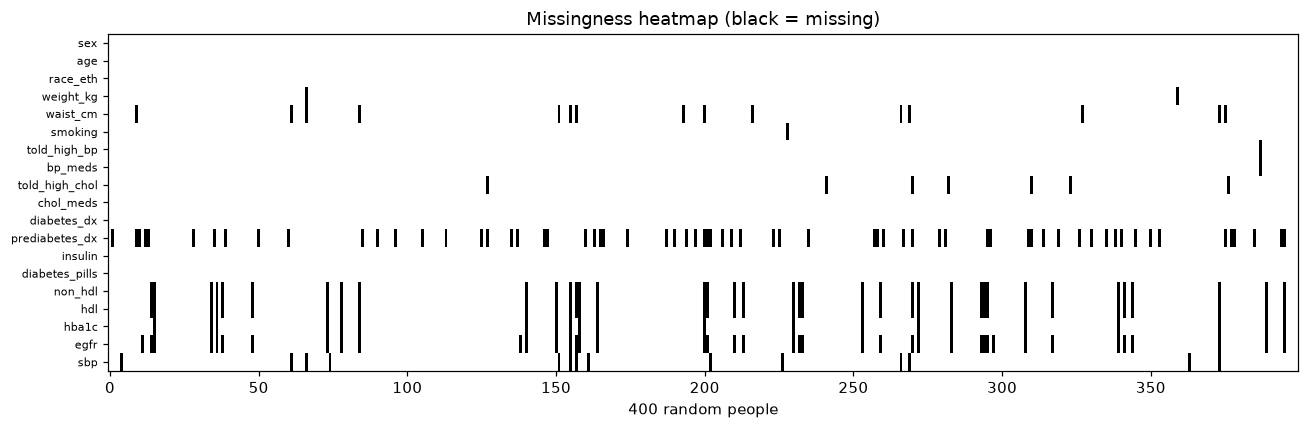

Takeaway: prediabetes_dx is missing most often (18%); the labs are missing together for people outside the lab subsample.


In [7]:
columns = [*FEATURES, *MODEL_ANALYTES]
missing_share = frame.select(pl.col(columns).is_null().mean())
sample = frame.sample(400, seed=1).select(pl.col(columns).is_null()).to_numpy()
fig, ax = plt.subplots(figsize=(12, 4))
ax.imshow(sample.T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(columns)), columns, fontsize=7)
ax.set_xlabel("400 random people")
ax.set_title("Missingness heatmap (black = missing)")
fig.tight_layout()
plt.show()
worst = max(columns, key=lambda c: missing_share[c][0])
print(
    f"Takeaway: {worst} is missing most often ({100 * missing_share[worst][0]:.0f}%); "
    "the labs are missing together for people outside "
    "the lab subsample."
)

shape: (1, 3)
┌──────────┬──────────┬────────────────────┐
│ wt_lab   ┆ wt_mec   ┆ people_with_wt_lab │
│ ---      ┆ ---      ┆ ---                │
│ f64      ┆ f64      ┆ u32                │
╞══════════╪══════════╪════════════════════╡
│ 2.3170e8 ┆ 2.3157e8 ┆ 5681               │
└──────────┴──────────┴────────────────────┘


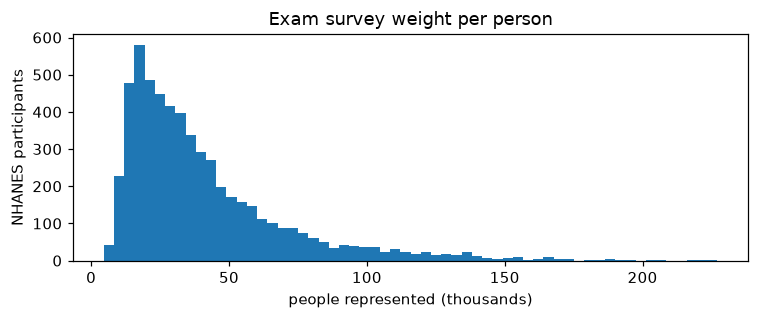

Takeaway: 5,681 participants stand for 232 million US adults; weights vary widely, so training and evaluation are weighted.


In [8]:
weights = frame.select(
    pl.col("wt_lab").drop_nulls().alias("wt_lab").sum(),
    pl.col("wt_mec").sum(),
    pl.col("wt_lab").is_not_null().sum().alias("people_with_wt_lab"),
)
print(weights)
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(frame["wt_mec"].drop_nulls().to_numpy() / 1000, bins=60)
ax.set_title("Exam survey weight per person")
ax.set_xlabel("people represented (thousands)")
ax.set_ylabel("NHANES participants")
fig.tight_layout()
plt.show()
print(
    f"Takeaway: {frame.height:,} participants stand for "
    f"{weights['wt_mec'][0] / 1e6:.0f} million US adults; "
    "weights vary widely, so training and evaluation "
    "are weighted."
)

## 3. Clean and process

**What and why.** We keep adults 20-79 who were examined and are not pregnant (PREVENT
and the prior are not meant for pregnancy), then for each target drop people without
that lab, values outside the plausible range (the same limits lab ingestion uses, so
training never learns from a value the API would reject), and rows with no survey weight.

In [9]:
with repository.engine.connect() as connection:

    def count(where: str) -> int:
        """Respondents in nhanes.demographics matching a SQL condition."""
        query = text(f"SELECT count(*) FROM nhanes.demographics WHERE {where}")
        return connection.execute(query).scalar_one()

    steps = [
        ("all respondents", count("true")),
        ("interviewed and examined", count("ridstatr = 2")),
        ("age 20-79", count("ridstatr = 2 AND ridageyr BETWEEN 20 AND 79")),
        (
            "not pregnant",
            count(
                "ridstatr = 2 AND ridageyr BETWEEN 20 AND 79 "
                "AND coalesce(ridexprg, 2) <> 1"
            ),
        ),
    ]
exclusions = pl.DataFrame(steps, schema=["step", "rows"], orient="row").with_columns(
    (pl.col("rows").shift(1) - pl.col("rows")).alias("dropped")
)
print(exclusions)
per_target = []
for name in MODEL_ANALYTES:
    raw = frame[name].cast(pl.Float64).fill_null(np.nan).to_numpy()
    kept = plausible_values(raw, name)
    weight = frame[TARGET_WEIGHTS[name]].cast(pl.Float64).fill_null(np.nan).to_numpy()
    per_target.append(
        {
            "target": name,
            "adults": frame.height,
            "missing_lab": int(np.isnan(raw).sum()),
            "implausible": int(np.isnan(kept).sum() - np.isnan(raw).sum()),
            "no_weight": int((~np.isnan(kept) & ~(weight > 0)).sum()),
            "used": int((~np.isnan(kept) & (weight > 0)).sum()),
        }
    )
per_target = pl.DataFrame(per_target)
per_target

shape: (4, 3)
┌──────────────────────────┬───────┬─────────┐
│ step                     ┆ rows  ┆ dropped │
│ ---                      ┆ ---   ┆ ---     │
│ str                      ┆ i64   ┆ i64     │
╞══════════════════════════╪═══════╪═════════╡
│ all respondents          ┆ 11933 ┆ null    │
│ interviewed and examined ┆ 8860  ┆ 3073    │
│ age 20-79                ┆ 5722  ┆ 3138    │
│ not pregnant             ┆ 5681  ┆ 41      │
└──────────────────────────┴───────┴─────────┘


target,adults,missing_lab,implausible,no_weight,used
str,i64,i64,i64,i64,i64
"""non_hdl""",5681,519,0,0,5162
"""hdl""",5681,519,0,0,5162
"""hba1c""",5681,272,0,0,5409
"""egfr""",5681,572,0,0,5109
"""sbp""",5681,177,0,0,5504


shape: (5, 7)
┌─────────┬───────────────┬────────┬───────────┬────────────┬───────────────┬────────────────┐
│ target  ┆ unit          ┆ min    ┆ median    ┆ max        ┆ plausible_low ┆ plausible_high │
│ ---     ┆ ---           ┆ ---    ┆ ---       ┆ ---        ┆ ---           ┆ ---            │
│ str     ┆ str           ┆ f64    ┆ f64       ┆ f64        ┆ f64           ┆ f64            │
╞═════════╪═══════════════╪════════╪═══════════╪════════════╪═══════════════╪════════════════╡
│ non_hdl ┆ mg/dL         ┆ 21.0   ┆ 131.0     ┆ 373.0      ┆ 20.0          ┆ 450.0          │
│ hdl     ┆ mg/dL         ┆ 22.0   ┆ 52.0      ┆ 159.0      ┆ 5.0           ┆ 200.0          │
│ hba1c   ┆ %             ┆ 3.2    ┆ 5.5       ┆ 17.1       ┆ 3.0           ┆ 20.0           │
│ egfr    ┆ mL/min/1.73m2 ┆ 3.5087 ┆ 94.512138 ┆ 143.351471 ┆ 2.0           ┆ 200.0          │
│ sbp     ┆ mmHg          ┆ 70.0   ┆ 120.0     ┆ 232.33     ┆ 60.0          ┆ 260.0          │
└─────────┴───────────────┴────────┴

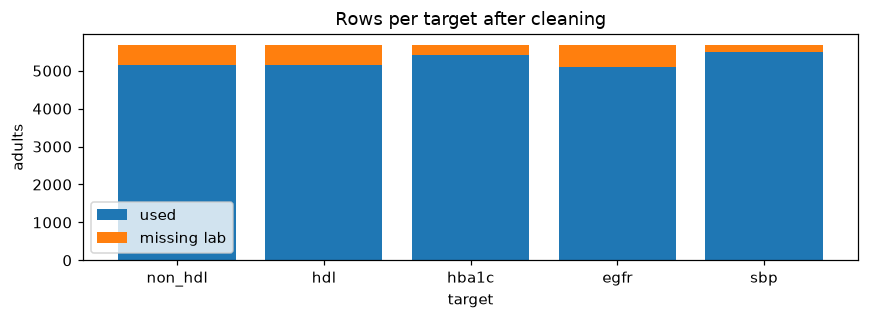

Takeaway: all values are already in canonical units and inside the plausible limits; missing labs are the only real loss (177-572 per target).


In [10]:
unit_checks = pl.DataFrame(
    [
        {
            "target": name,
            "unit": UNITS[name],
            "min": frame[name].min(),
            "median": frame[name].median(),
            "max": frame[name].max(),
            "plausible_low": ANALYTES[name].plausible[0],
            "plausible_high": ANALYTES[name].plausible[1],
        }
        for name in MODEL_ANALYTES
    ]
)
print(unit_checks)
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(per_target["target"].to_list(), per_target["used"].to_list(), label="used")
ax.bar(
    per_target["target"].to_list(),
    per_target["missing_lab"].to_list(),
    bottom=per_target["used"].to_list(),
    label="missing lab",
)
ax.set_title("Rows per target after cleaning")
ax.set_xlabel("target")
ax.set_ylabel("adults")
ax.legend()
fig.tight_layout()
plt.show()
lost_low, lost_high = per_target["missing_lab"].min(), per_target["missing_lab"].max()
print(
    "Takeaway: all values are already in canonical units "
    "and inside the plausible limits; missing labs are "
    f"the only real loss ({lost_low:,}-{lost_high:,} per "
    "target)."
)

## 4. Feature engineering

**What and why.** Three derived values: BMI (weight / height^2, used by PREVENT), eGFR
with the race-free CKD-EPI 2021 equation (the one PREVENT was derived with), and
non-HDL cholesterol (total minus HDL from the same draw). The engine computes these
itself, never the extractor. Categorical features are encoded with fixed levels so a
single API profile encodes exactly like training data.

In [11]:
person = frame.filter(
    pl.col("bmi").is_not_null() & pl.col("non_hdl").is_not_null()
).row(0, named=True)
weight, height = person["weight_kg"], person["height_cm"]
bmi = weight / (height / 100) ** 2
total_chol = person["non_hdl"] + person["hdl"]
man, woman = egfr_ckd_epi_2021(1.0, 50, 1), egfr_ckd_epi_2021(1.0, 50, 2)
print(f"BMI: {weight} kg / ({height} cm / 100)^2 = {bmi:.1f} (table: {person['bmi']})")
print(
    f"Non-HDL: total cholesterol {total_chol:.0f} - HDL "
    f"{person['hdl']:.0f} = {person['non_hdl']:.0f} mg/dL"
)
print(
    "eGFR (CKD-EPI 2021), creatinine 1.0 mg/dL at 50: "
    f"man {man:.1f}, woman {woman:.1f} mL/min/1.73m2"
)
features = prepare_features(frame, bundle.category_levels)
pl.DataFrame(features[:5], schema=list(FEATURES), orient="row")

BMI: 86.9 kg / (179.5 cm / 100)^2 = 27.0 (table: 27.0)
Non-HDL: total cholesterol 264 - HDL 45 = 219 mg/dL
eGFR (CKD-EPI 2021), creatinine 1.0 mg/dL at 50: man 91.7, woman 68.6 mL/min/1.73m2


sex,age,race_eth,weight_kg,waist_cm,smoking,told_high_bp,bp_meds,told_high_chol,chol_meds,diabetes_dx,prediabetes_dx,insulin,diabetes_pills
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.0,43.0,4.0,86.9,98.3,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
0.0,66.0,2.0,101.8,114.7,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1.0,44.0,1.0,69.4,93.5,0.0,0.0,0.0,1.0,1.0,1.0,NaN,0.0,1.0
0.0,34.0,0.0,90.6,106.1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1.0,68.0,2.0,103.5,122.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0


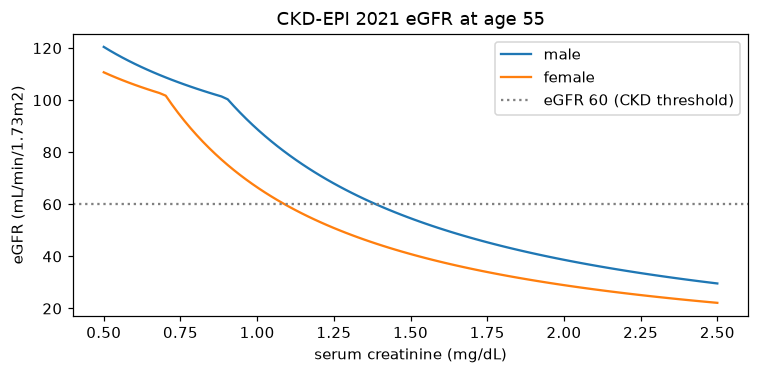

Takeaway: at the same creatinine a woman's eGFR is lower; a 55-year-old man crosses 60 near 1.39 mg/dL.


In [12]:
creatinine = np.linspace(0.5, 2.5, 100)
fig, ax = plt.subplots(figsize=(7, 3.5))
for sex, label in ((1, "male"), (2, "female")):
    ax.plot(
        creatinine,
        [egfr_ckd_epi_2021(value, 55, sex) for value in creatinine],
        label=label,
    )
ax.axhline(60, color="grey", ls=":", label="eGFR 60 (CKD threshold)")
ax.set_title("CKD-EPI 2021 eGFR at age 55")
ax.set_xlabel("serum creatinine (mg/dL)")
ax.set_ylabel("eGFR (mL/min/1.73m2)")
ax.legend()
fig.tight_layout()
plt.show()
male_egfr = np.array([egfr_ckd_epi_2021(value, 55, 1) for value in creatinine])
threshold = creatinine[np.argmin(np.abs(male_egfr - 60))]
print(
    "Takeaway: at the same creatinine a woman's eGFR "
    f"is lower; a 55-year-old man crosses 60 near {threshold:.2f} "
    "mg/dL."
)

## 5. Train the quantile prior

**What and why.** One LightGBM quantile model per target and quantile (p10, p50, p90),
survey-weighted. Cross-validation is grouped by NHANES design cluster (stratum x PSU) so
people from one sampled area are never on both sides of a split. The p10-p90 band is
then calibrated per sex x age band (Mondrian conformal) on out-of-fold predictions.
Below: the settings, the grouped split, and the time to train one target.

Quick win tested (goals doc, section 3): adding clinic pulse as a feature changed
holdout pinball loss by -0.3% to +0.5% per target (non-HDL -0.29%, HDL -0.14%,
HbA1c +0.51%, eGFR +0.51%, SBP +0.22%), so pulse was not added and wearable resting
heart rate is not fed into the prior.

In [13]:
print("quantiles:", QUANTILES, "| learning rate:", LEARNING_RATE, "| folds:", N_SPLITS)
print("configurations compared:", PARAM_GRID)
clusters = design_clusters(frame)
print(f"design clusters: {len(np.unique(clusters))} (stratum x PSU)")
values = plausible_values(
    frame["hdl"].cast(pl.Float64).fill_null(np.nan).to_numpy(), "hdl"
)
weights = frame["wt_lab"].cast(pl.Float64).fill_null(np.nan).to_numpy()
started = time.perf_counter()
hdl_training = train_target(features, values, weights, clusters, "hdl")
elapsed = time.perf_counter() - started
print(
    f"HDL trained in {elapsed:.0f} s; chosen config {hdl_training.cv_summary['config']}"
)
pl.DataFrame(
    [
        {"target": target, "config": cv["config"], "mean_pinball": cv["mean_pinball"]}
        for target, cv in bundle.metrics["cv"].items()
    ]
)

quantiles: (0.1, 0.5, 0.9) | learning rate: 0.03 | folds: 5
configurations compared: [{'num_leaves': 15, 'min_child_samples': 20}, {'num_leaves': 15, 'min_child_samples': 50}, {'num_leaves': 31, 'min_child_samples': 20}, {'num_leaves': 31, 'min_child_samples': 50}]
design clusters: 30 (stratum x PSU)


2026-11-04 06:55:08,513 - src.components.model_trainer - INFO -   leaves15_mcs20: mean pinball=2.9862


2026-11-04 06:55:15,860 - src.components.model_trainer - INFO -   leaves15_mcs50: mean pinball=2.9845


2026-11-04 06:55:26,796 - src.components.model_trainer - INFO -   leaves31_mcs20: mean pinball=3.0020


2026-11-04 06:55:37,226 - src.components.model_trainer - INFO -   leaves31_mcs50: mean pinball=2.9888


2026-11-04 06:55:41,386 - src.pipeline.training_pipeline - INFO - best for hdl: leaves15_mcs50 (avg pinball=2.9845)


2026-11-04 06:55:42,282 - src.pipeline.training_pipeline - INFO - hdl holdout coverage=0.820 width=30.01; cross-conformal gap sex=0.2 age=0.2 pts


HDL trained in 42 s; chosen config leaves15_mcs50


target,config,mean_pinball
str,str,f64
"""non_hdl""","""leaves15_mcs50""",8.943802
"""hdl""","""leaves15_mcs50""",2.984452
"""hba1c""","""leaves15_mcs50""",0.141283
"""egfr""","""leaves15_mcs20""",3.487976
"""sbp""","""leaves15_mcs50""",3.428873


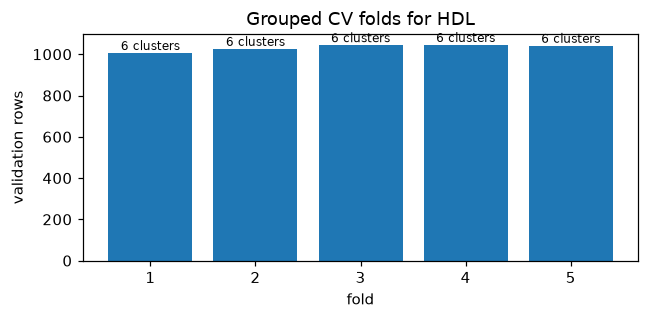

Takeaway: each fold validates on whole clusters (6-6 per fold), so the CV loss reflects new areas, not new rows from known ones.


In [14]:
from sklearn.model_selection import GroupKFold

usable = ~np.isnan(values) & (weights > 0)
fold_sizes = [
    (len(np.unique(clusters[usable][test])), int(test.size))
    for _, test in GroupKFold(n_splits=N_SPLITS).split(
        features[usable], groups=clusters[usable]
    )
]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(1, N_SPLITS + 1), [size for _, size in fold_sizes])
for fold, (n_clusters, size) in enumerate(fold_sizes, start=1):
    ax.text(fold, size, f"{n_clusters} clusters", ha="center", va="bottom", fontsize=8)
ax.set_title("Grouped CV folds for HDL")
ax.set_xlabel("fold")
ax.set_ylabel("validation rows")
fig.tight_layout()
plt.show()
cluster_counts = [n_clusters for n_clusters, _ in fold_sizes]
print(
    "Takeaway: each fold validates on whole clusters "
    f"({min(cluster_counts)}-{max(cluster_counts)} per "
    "fold), so the CV loss reflects new areas, not new "
    "rows from known ones."
)

## 6. Evaluate the prior (goals 2-4)

**What and why.** The prior's tuned settings are refit on the grouped training split and
scored on the untouched held-out clusters, weighted to US adults: accuracy of the median,
coverage of the 80% band (goal 2: 75-85%), band width (the yardstick for goal 3), and
coverage by sex and age band (goal 4: gap at most 5 points).

In [15]:
holdout = {}
for name in tqdm(MODEL_ANALYTES, desc="Refitting priors on the training split"):
    train, test = grouped_split(frame, name)
    holdout[name] = (test, holdout_predictions(bundle, train, test, name))

rows = []
for name, (test, bands) in holdout.items():
    actual = test[name].cast(pl.Float64).to_numpy()
    weight = test[TARGET_WEIGHTS[name]].cast(pl.Float64).to_numpy()
    error = bands[:, 1] - actual
    rows.append(
        {
            "target": name,
            "held_out_rows": test.height,
            "MAE": float(np.average(np.abs(error), weights=weight)),
            "median_abs_error": float(np.median(np.abs(error))),
            "coverage_80": float(
                np.average(
                    (actual >= bands[:, 0]) & (actual <= bands[:, 2]), weights=weight
                )
            ),
            "band_width": float(np.average(bands[:, 2] - bands[:, 0], weights=weight)),
        }
    )
prior_metrics = pl.DataFrame(rows)
prior_metrics.with_columns(pl.selectors.float().round(3))

Refitting priors on the training split:   0%|          | 0/5 [00:00<?, ?it/s]

target,held_out_rows,MAE,median_abs_error,coverage_80,band_width
str,i64,f64,f64,f64,f64
"""non_hdl""",1021,26.117,20.925,0.82,90.99
"""hdl""",1021,8.801,7.178,0.82,30.013
"""hba1c""",1082,0.398,0.244,0.82,1.187
"""egfr""",1014,12.548,10.807,0.796,35.469
"""sbp""",1118,11.255,9.535,0.793,34.7


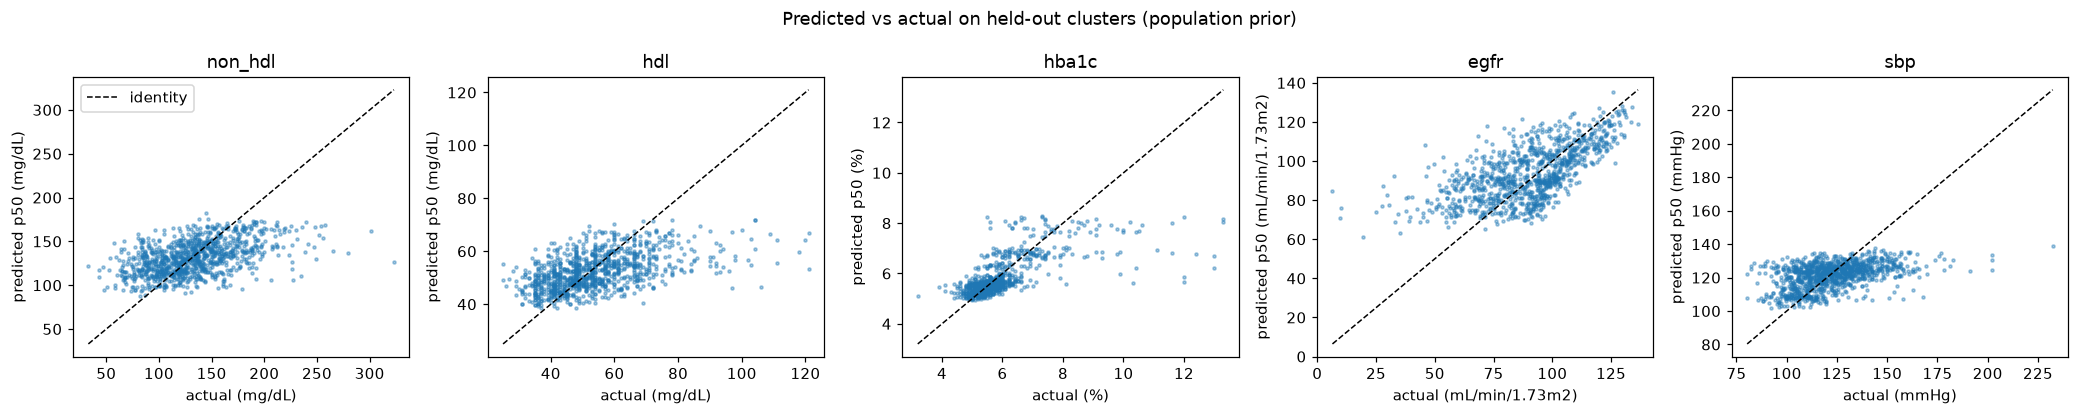

Takeaway: the prior captures the population trend but is far from each person's value; that gap is what a lab closes.


In [16]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, name in zip(axes, MODEL_ANALYTES, strict=True):
    test, bands = holdout[name]
    actual = test[name].cast(pl.Float64).to_numpy()
    ax.scatter(actual, bands[:, 1], s=4, alpha=0.4)
    limits = [
        min(actual.min(), bands[:, 1].min()),
        max(actual.max(), bands[:, 1].max()),
    ]
    ax.plot(limits, limits, "k--", lw=1, label="identity")
    ax.set_title(name)
    ax.set_xlabel(f"actual ({UNITS[name]})")
    ax.set_ylabel(f"predicted p50 ({UNITS[name]})")
axes[0].legend()
fig.suptitle("Predicted vs actual on held-out clusters (population prior)")
fig.tight_layout()
plt.show()
print(
    "Takeaway: the prior captures the population trend "
    "but is far from each person's value; that gap is "
    "what a lab closes."
)

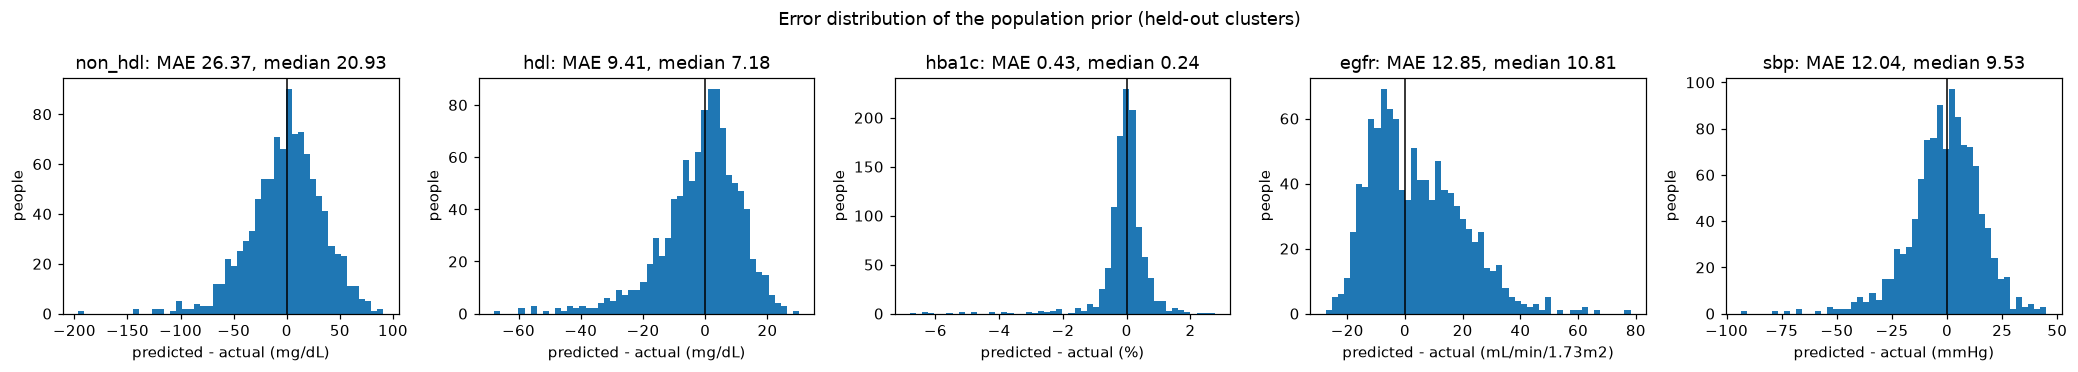

Takeaway: errors centre near zero (unbiased) but are wide, and the long right tails come from the skewed targets.


In [17]:
fig, axes = plt.subplots(1, 5, figsize=(19, 3.4))
for ax, name in zip(axes, MODEL_ANALYTES, strict=True):
    test, bands = holdout[name]
    error = bands[:, 1] - test[name].cast(pl.Float64).to_numpy()
    ax.hist(error, bins=50)
    ax.axvline(0, color="k", lw=1)
    mae, median_error = np.mean(np.abs(error)), np.median(np.abs(error))
    ax.set_title(f"{name}: MAE {mae:.2f}, median {median_error:.2f}")
    ax.set_xlabel(f"predicted - actual ({UNITS[name]})")
    ax.set_ylabel("people")
fig.suptitle("Error distribution of the population prior (held-out clusters)")
fig.tight_layout()
plt.show()
print(
    "Takeaway: errors centre near zero (unbiased) but "
    "are wide, and the long right tails come from the "
    "skewed targets."
)

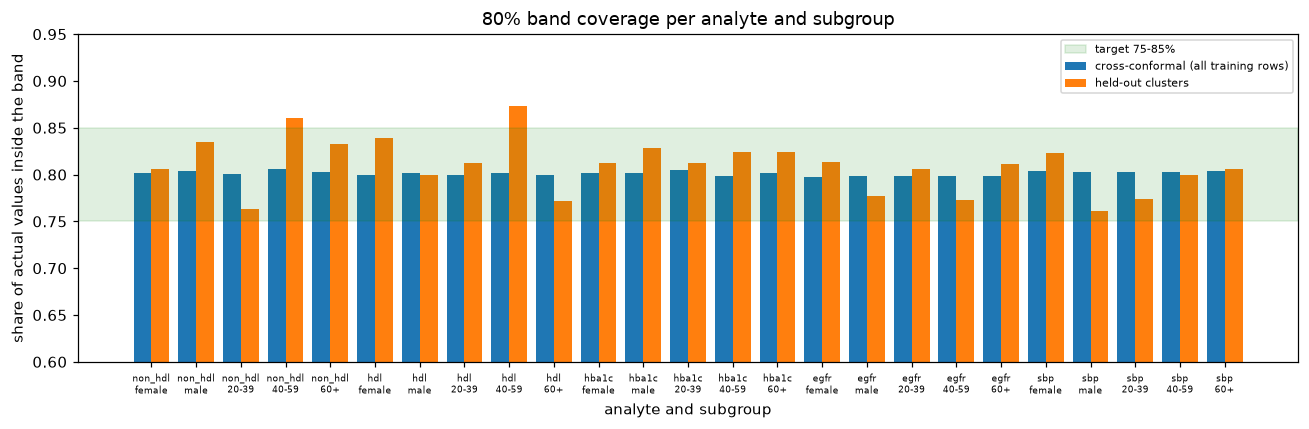

Takeaway: overall coverage is 0.79-0.82 (goal 2 met); the largest cross-conformal subgroup gap is 0.7 points (goal 4 met). Held-out subgroup bars are noisier: each group has only a few hundred people from a few clusters.


In [18]:
subgroup_rows = []
for name, (test, bands) in holdout.items():
    actual = test[name].cast(pl.Float64).to_numpy()
    covered = ((actual >= bands[:, 0]) & (actual <= bands[:, 2])).astype(float)
    weight = test[TARGET_WEIGHTS[name]].cast(pl.Float64).to_numpy()
    groups = calibration_groups(prepare_features(test, bundle.category_levels))
    report = subgroup_coverage(covered, weight, groups)
    cross = bundle.metrics["subgroups"][name]["cross_conformal"]
    for dimension in ("sex", "age_band"):
        for group, share in report[dimension].items():
            if group != "gap":
                subgroup_rows.append(
                    {
                        "target": name,
                        "dimension": dimension,
                        "group": group,
                        "holdout": share,
                        "cross_conformal": cross[dimension][group],
                    }
                )
subgroups = pl.DataFrame(subgroup_rows)

fig, ax = plt.subplots(figsize=(12, 4))
labels = [f"{r['target']}\n{r['group']}" for r in subgroup_rows]
positions = np.arange(len(subgroup_rows))
ax.bar(
    positions - 0.2,
    subgroups["cross_conformal"].to_list(),
    0.4,
    label="cross-conformal (all training rows)",
)
ax.bar(positions + 0.2, subgroups["holdout"].to_list(), 0.4, label="held-out clusters")
ax.axhspan(0.75, 0.85, color="green", alpha=0.12, label="target 75-85%")
ax.set_xticks(positions, labels, fontsize=6)
ax.set_ylim(0.6, 0.95)
ax.set_title("80% band coverage per analyte and subgroup")
ax.set_xlabel("analyte and subgroup")
ax.set_ylabel("share of actual values inside the band")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
largest_gap = max(
    bundle.metrics["subgroups"][name]["cross_conformal"][dimension]["gap"]
    for name in MODEL_ANALYTES
    for dimension in ("sex", "age_band")
)
low, high = prior_metrics["coverage_80"].min(), prior_metrics["coverage_80"].max()
print(
    f"Takeaway: overall coverage is {low:.2f}-{high:.2f} "
    "(goal 2 met); the largest cross-conformal subgroup "
    f"gap is {largest_gap:.1f} points (goal 4 met). Held-out "
    "subgroup bars are noisier: each group has only a "
    "few hundred people from a few clusters."
)

## 7. Ingest a lab in the input format

**What and why.** The extractor sends a JSON array of records in one fixed shape. The
sample file has one complete panel, one partial panel in SI units (HDL in mmol/L, HbA1c
in mmol/mol) and one record with a bad unit. Each record is mapped to a canonical analyte,
converted to its canonical unit, checked against plausibility limits and the measurement
method, or rejected with a reason. Non-HDL and eGFR are then derived by the engine.

In [19]:
lab_records = orjson.loads((FIXTURES / "sample_lab_records.json").read_bytes())
print(f"Records in the sample file: {len(lab_records)}")
pl.DataFrame(lab_records).head(10)

Records in the sample file: 8


id,biomarker_abbr,value,unit,measurement_method,measured_at
str,str,f64,str,str,str
"""7fc19c93-c0a5-5d85-aa0d-8e0535…","""TC""",228.0,"""mg/dL""","""blood_test_lab_report_upload""","""2026-05-04T08:15:00.000Z"""
"""c71b15fc-9d69-58b6-b13a-6774f6…","""HDL""",41.0,"""mg/dL""","""blood_test_lab_report_upload""","""2026-05-04T08:15:00.000Z"""
"""12478085-6728-5f7e-bb72-d978da…","""HBA1C""",5.9,"""%""","""blood_test_lab_report_upload""","""2026-05-04T08:15:00.000Z"""
"""493306ae-24b2-50e9-9855-30baec…","""CREAT""",1.02,"""mg/dL""","""blood_test_lab_report_upload""","""2026-05-04T08:15:00.000Z"""
"""0fc4a0e8-3d2b-5a79-b074-6e368a…","""SBP""",136.0,"""mmHg""","""home_bp_protocol""","""2026-05-04T08:15:00.000Z"""
"""04a1f606-e0b7-5e26-b76a-dc8baf…","""HDL-C""",1.22,"""mmol/L""","""blood_test_lab_report_upload""","""2026-08-17T07:40:00.000Z"""
"""175309c1-6f5b-5889-a75b-f9e965…","""Hemoglobin A1c""",43.0,"""mmol/mol""","""blood_test_lab_report_upload""","""2026-08-17T07:40:00.000Z"""
"""691d5f69-8e63-5193-b501-78d163…","""HDL""",0.47,"""g/L""","""blood_test_lab_report_upload""","""2026-08-17T07:40:00.000Z"""


In [20]:
PERSONA = {
    "sex": 1,
    "age": 55,
    "race_eth": 3,
    "height_cm": 180.0,
    "weight_kg": 89.0,
    "waist_cm": 100.0,
    "smoking": "never",
    "told_high_bp": 0,
    "bp_meds": 0,
    "told_high_chol": 1,
    "chol_meds": 0,
    "diabetes_dx": "no",
    "prediabetes_dx": 0,
    "insulin": 0,
    "diabetes_pills": 0,
}
ingested = ingest_records(lab_records, PERSONA["age"], PERSONA["sex"])
accepted = pl.DataFrame(
    [
        {
            "analyte": m.analyte,
            "value": round(m.value, 2),
            "unit": ANALYTES[m.analyte].unit,
            "measured_at": m.measured_at.date(),
            "derived_from": len(m.derived_from),
        }
        for m in ingested.labs
    ]
)
rejected = pl.DataFrame(
    [
        {"id": r.record_id, "biomarker_abbr": r.biomarker_abbr, "reason": r.reason}
        for r in ingested.rejected
    ]
)
derived = int((accepted["derived_from"] > 0).sum())
kept = len(lab_records) - rejected.height
print(
    f"Records in: {len(lab_records)} | accepted: {kept} "
    f"| derived: {derived} | rejected: {rejected.height}"
)
print(rejected)
accepted

2026-11-04 06:55:48,380 - src.components.record_ingestion - WARNING - Rejected record 691d5f69-8e63-5193-b501-78d163402b71 (HDL): unit 'g/L' is not supported for hdl


Records in: 8 | accepted: 7 | derived: 2 | rejected: 1
shape: (1, 3)
┌─────────────────────────────────┬────────────────┬─────────────────────────────────┐
│ id                              ┆ biomarker_abbr ┆ reason                          │
│ ---                             ┆ ---            ┆ ---                             │
│ str                             ┆ str            ┆ str                             │
╞═════════════════════════════════╪════════════════╪═════════════════════════════════╡
│ 691d5f69-8e63-5193-b501-78d163… ┆ HDL            ┆ unit 'g/L' is not supported fo… │
└─────────────────────────────────┴────────────────┴─────────────────────────────────┘


analyte,value,unit,measured_at,derived_from
str,f64,str,date,i64
"""total_chol""",228.0,"""mg/dL""",2026-05-04,0
"""hdl""",41.0,"""mg/dL""",2026-05-04,0
"""hba1c""",5.9,"""%""",2026-05-04,0
"""creatinine""",1.02,"""mg/dL""",2026-05-04,0
"""sbp""",136.0,"""mmHg""",2026-05-04,0
"""non_hdl""",187.0,"""mg/dL""",2026-05-04,2
"""egfr""",86.8,"""mL/min/1.73m2""",2026-05-04,1
"""hdl""",47.18,"""mg/dL""",2026-08-17,0
"""hba1c""",6.09,"""%""",2026-08-17,0


**Takeaway.** The SI-unit partial panel is converted (HDL 1.22 mmol/L becomes 47.2 mg/dL,
HbA1c 43 mmol/mol becomes 6.1%), the g/L record is rejected with its reason, and
non-HDL and eGFR appear as engine-derived values from the complete panel.

## 8. Lab-anchored band (goals 1, 3, 5)

**What and why.** Before any lab the user gets the population band. After a lab the
band is centred on that lab, with a width set by published within-person variation:
sqrt(2) x the measurement SD plus drift that grows with the lab's age, so the 80% band
predicts the user's next lab. The activation registry serves the lab band only where it
beat the population band in the simulation below ("never worse").

In [21]:
as_of = date(2026, 5, 4)
before = twin_state(engine, TwinRequest(profile=PERSONA, as_of=as_of))
after = twin_state(
    engine, TwinRequest(profile=PERSONA, records=lab_records, as_of=as_of)
)
comparison = pl.DataFrame(
    [
        {
            "analyte": b.analyte,
            "unit": b.unit,
            "population_band": f"{b.p10:.1f}-{b.p90:.1f}",
            "population_width": b.p90 - b.p10,
            "basis_after": a.basis,
            "lab_band": f"{a.p10:.1f}-{a.p90:.1f}",
            "lab_width": a.p90 - a.p10,
        }
        for b, a in zip(before.predictions, after.predictions, strict=True)
    ]
).with_columns((pl.col("lab_width") / pl.col("population_width")).alias("width_ratio"))
comparison.with_columns(pl.selectors.float().round(2))

2026-11-04 06:55:48,713 - src.components.record_ingestion - WARNING - Rejected record 691d5f69-8e63-5193-b501-78d163402b71 (HDL): unit 'g/L' is not supported for hdl


analyte,unit,population_band,population_width,basis_after,lab_band,lab_width,width_ratio
str,str,str,f64,str,str,f64,f64
"""non_hdl""","""mg/dL""","""119.8-224.1""",104.33,"""lab""","""164.7-212.3""",47.52,0.46
"""hdl""","""mg/dL""","""36.5-64.8""",28.27,"""lab""","""36.4-46.1""",9.67,0.34
"""hba1c""","""%""","""4.9-5.9""",0.92,"""lab""","""5.6-6.2""",0.53,0.58
"""egfr""","""mL/min/1.73m2""","""72.4-104.3""",31.88,"""lab""","""77.9-96.8""",18.9,0.59
"""sbp""","""mmHg""","""108.3-136.3""",27.98,"""lab""","""122.0-151.6""",29.61,1.06


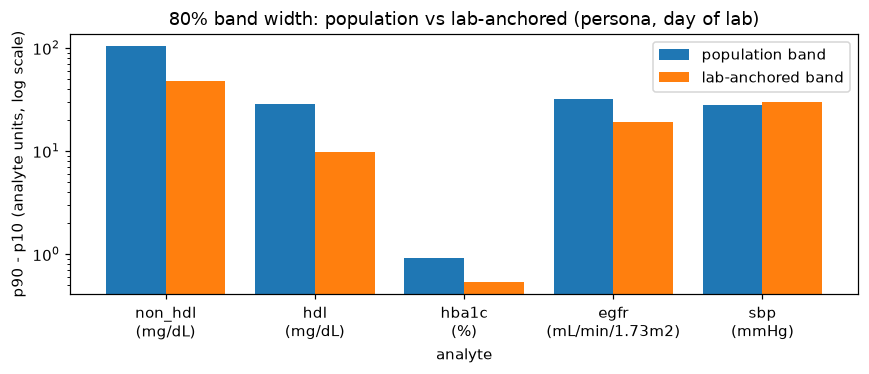

Takeaway: lab band as a share of the population band for this persona: non_hdl 46%, hdl 34%, hba1c 58%, egfr 59%, sbp 106%. Lipids and eGFR narrow sharply; SBP barely does, because one home BP reading varies about as much as people of this profile do.


In [22]:
fig, ax = plt.subplots(figsize=(8, 3.5))
positions = np.arange(len(MODEL_ANALYTES))
ax.bar(
    positions - 0.2,
    comparison["population_width"].to_list(),
    0.4,
    label="population band",
)
ax.bar(
    positions + 0.2, comparison["lab_width"].to_list(), 0.4, label="lab-anchored band"
)
ax.set_xticks(positions, [f"{n}\n({UNITS[n]})" for n in MODEL_ANALYTES])
ax.set_yscale("log")
ax.set_title("80% band width: population vs lab-anchored (persona, day of lab)")
ax.set_xlabel("analyte")
ax.set_ylabel("p90 - p10 (analyte units, log scale)")
ax.legend()
fig.tight_layout()
plt.show()
ratios = ", ".join(
    f"{n} {r:.0%}"
    for n, r in zip(comparison["analyte"], comparison["width_ratio"], strict=True)
)
print(
    "Takeaway: lab band as a share of the population "
    f"band for this persona: {ratios}. Lipids and eGFR "
    "narrow sharply; SBP barely does, because one home "
    "BP reading varies about as much as people of this "
    "profile do."
)

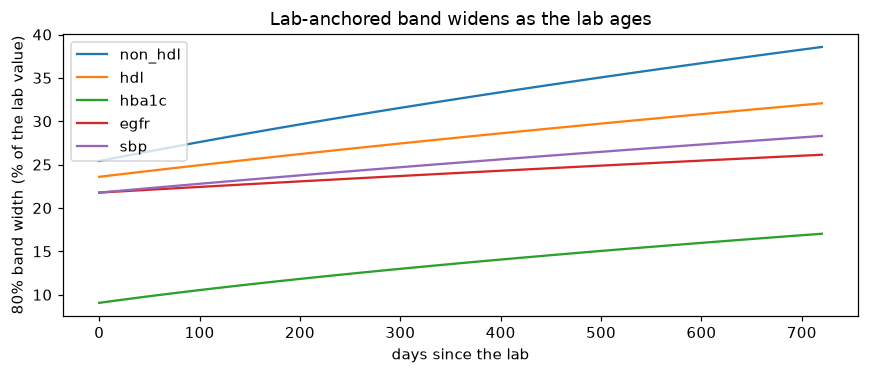

Takeaway: the band starts at the measurement noise floor and widens with within-person drift, so an old lab is trusted less.


In [23]:
days = np.arange(0, 731, 15)
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in MODEL_ANALYTES:
    sigma = np.array([lab_sigma(name, d) for d in days])
    width_pct = 100 * (np.exp(1.2816 * sigma) - np.exp(-1.2816 * sigma))
    ax.plot(days, width_pct, label=name)
ax.set_title("Lab-anchored band widens as the lab ages")
ax.set_xlabel("days since the lab")
ax.set_ylabel("80% band width (% of the lab value)")
ax.legend()
fig.tight_layout()
plt.show()
print(
    "Takeaway: the band starts at the measurement noise "
    "floor and widens with within-person drift, so an "
    "old lab is trusted less."
)

In [24]:
goal_rows = [
    {
        "analyte": name,
        "lab_stage_served": decision.active,
        "error_reduction": decision.evidence["error_reduction"],
        "goal1_met (>=40%)": decision.evidence["goal1_error_reduction_met"],
        "lab_coverage_80": decision.evidence["lab_coverage_80"],
        "goal2_met (75-85%)": decision.evidence["goal2_coverage_met"],
        "width_ratio": decision.evidence["width_ratio"],
        "best_possible_ratio": decision.evidence["min_width_ratio_possible"],
        "goal3_met (<=1/3)": decision.evidence["goal3_width_met"],
        "false_alert_rate": decision.evidence["false_alert_rate"],
        "goal5_met (<=5%)": decision.evidence["goal5_false_alerts_met"],
    }
    for name, decision in registry.lab.items()
]
pl.DataFrame(goal_rows).with_columns(pl.selectors.float().round(3))

analyte,lab_stage_served,error_reduction,goal1_met (>=40%),lab_coverage_80,goal2_met (75-85%),width_ratio,best_possible_ratio,goal3_met (<=1/3),false_alert_rate,goal5_met (<=5%)
str,bool,f64,bool,f64,bool,f64,f64,bool,f64,bool
"""non_hdl""",true,0.53,true,0.819,true,0.445,0.374,false,0.043,true
"""hdl""",true,0.509,true,0.821,true,0.473,0.419,false,0.043,true
"""hba1c""",true,0.291,false,0.795,true,0.583,0.434,false,0.048,true
"""egfr""",true,0.477,true,0.812,true,0.602,0.564,false,0.045,true
"""sbp""",true,0.264,false,0.801,true,0.827,0.75,false,0.057,false


**Takeaway (simulation with published within-person variation, NHANES held-out people
as true levels).** The lab band keeps 80% coverage (goal 2) and false real-change alerts
near 5% (goal 5) for every analyte, and cuts next-lab error by at least 40% (goal 1) for
non-HDL, HDL and eGFR. HbA1c and SBP fall short of 40% because their population spread
is already narrow relative to within-person drift. Goal 3 (band at most one third of the
population width) is not reachable for any analyte: `best_possible_ratio` is the width of
a band from a lab taken today, set by measurement noise alone, and it is above one third
everywhere. These are simulation results; real repeat labs decide after launch.

Building the HDL fan chart:   0%|          | 0/100 [00:00<?, ?it/s]

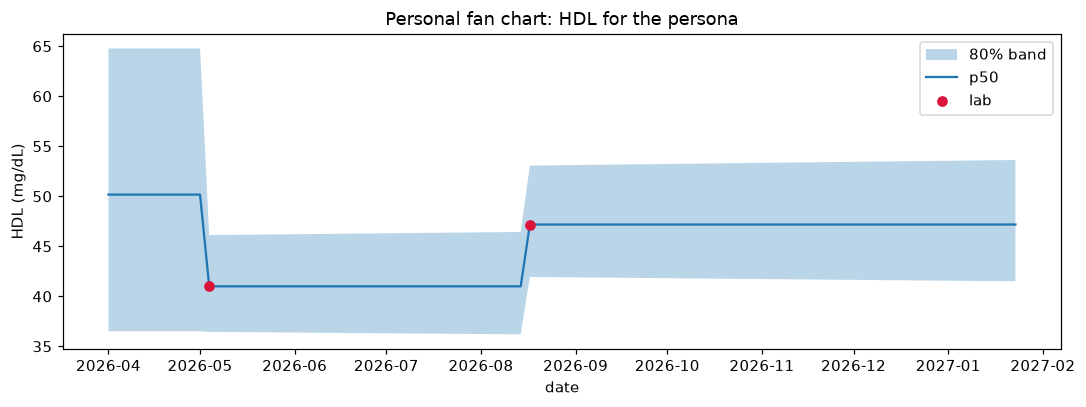

Takeaway: before the first lab the band is the wide population band; each lab re-centres it and it widens slowly until the next lab.


In [25]:
fan_labs = [*lab_records[:5], *lab_records[5:7]]
days_axis = [date(2026, 4, 1) + timedelta(days=d) for d in range(0, 300, 3)]
fan = [
    next(
        p
        for p in twin_state(
            engine, TwinRequest(profile=PERSONA, records=fan_labs, as_of=day)
        ).predictions
        if p.analyte == "hdl"
    )
    for day in tqdm(days_axis, desc="Building the HDL fan chart")
]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(
    days_axis, [p.p10 for p in fan], [p.p90 for p in fan], alpha=0.3, label="80% band"
)
ax.plot(days_axis, [p.p50 for p in fan], label="p50")
lab_points = [
    (m.measured_at.date(), m.value) for m in ingested.labs if m.analyte == "hdl"
]
ax.scatter(
    [d for d, _ in lab_points],
    [v for _, v in lab_points],
    color="crimson",
    zorder=5,
    label="lab",
)
ax.set_title("Personal fan chart: HDL for the persona")
ax.set_xlabel("date")
ax.set_ylabel("HDL (mg/dL)")
ax.legend()
fig.tight_layout()
plt.show()
print(
    "Takeaway: before the first lab the band is the wide "
    "population band; each lab re-centres it and it widens "
    "slowly until the next lab."
)

## 8a. Wearables: ingest daily summaries

**What and why.** Wearable daily summaries use the same record shape as labs, so the
same pipeline accepts them (scale weight in pounds is converted to kg). Coverage per
metric matters because a window is only used with at least 70% of its days covered.

In [26]:
wearable_records = orjson.loads(
    (FIXTURES / "sample_wearable_records.json").read_bytes()
)
wearables = ingest_records(wearable_records, PERSONA["age"], PERSONA["sex"]).wearables
print(f"Records in: {len(wearable_records)} | accepted: {len(wearables)}")
coverage = pl.DataFrame(
    [
        {
            "metric": metric,
            "days_with_data": len(daily_values(wearables, metric, date(2026, 8, 28))),
            "span_days": 120,
        }
        for metric in WEARABLE_METRICS
    ]
).with_columns((pl.col("days_with_data") / pl.col("span_days")).alias("daily_coverage"))
print(coverage)
pl.DataFrame(
    [{"metric": m.analyte, "value": m.value, "day": m.day} for m in wearables]
).head(5)

Records in: 310 | accepted: 310
shape: (4, 4)
┌────────────────────┬────────────────┬───────────┬────────────────┐
│ metric             ┆ days_with_data ┆ span_days ┆ daily_coverage │
│ ---                ┆ ---            ┆ ---       ┆ ---            │
│ str                ┆ i64            ┆ i64       ┆ f64            │
╞════════════════════╪════════════════╪═══════════╪════════════════╡
│ resting_heart_rate ┆ 111            ┆ 120       ┆ 0.925          │
│ hrv_rmssd          ┆ 111            ┆ 120       ┆ 0.925          │
│ vo2_max            ┆ 18             ┆ 120       ┆ 0.15           │
│ weight             ┆ 70             ┆ 120       ┆ 0.583333       │
└────────────────────┴────────────────┴───────────┴────────────────┘


metric,value,day
str,f64,date
"""resting_heart_rate""",64.4,2026-05-01
"""hrv_rmssd""",36.9,2026-05-01
"""vo2_max""",35.6,2026-05-01
"""resting_heart_rate""",64.1,2026-05-02
"""hrv_rmssd""",43.4,2026-05-02


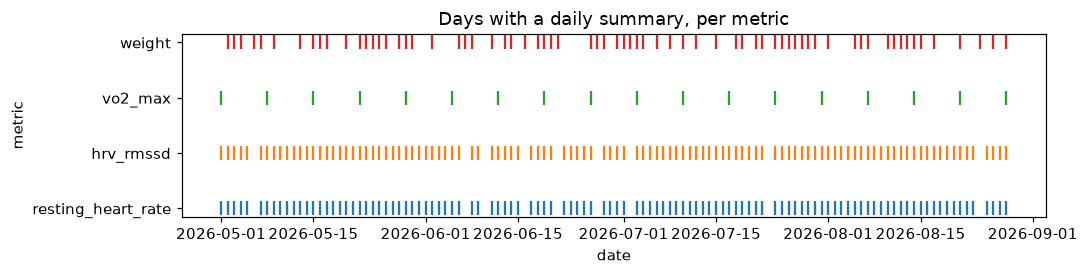

Takeaway: resting HR and HRV cover 92% of days; weekly VO2 max never reaches 70% coverage, so its windows are marked insufficient.


In [27]:
fig, ax = plt.subplots(figsize=(10, 2.6))
for row, metric in enumerate(WEARABLE_METRICS):
    days_present = sorted(daily_values(wearables, metric, date(2026, 8, 28)))
    ax.scatter(days_present, [row] * len(days_present), marker="|", s=80)
ax.set_yticks(range(len(WEARABLE_METRICS)), WEARABLE_METRICS)
ax.set_title("Days with a daily summary, per metric")
ax.set_xlabel("date")
ax.set_ylabel("metric")
fig.tight_layout()
plt.show()
print(
    f"Takeaway: resting HR and HRV cover {coverage['daily_coverage'][0]:.0%} "
    "of days; weekly VO2 max never reaches 70% coverage, "
    "so its windows are marked insufficient."
)

## 8b. Wearables: 30- and 90-day windows

**What and why.** For each metric, windows ending at as_of give the mean, SD, Theil-Sen
slope (robust to outlier days) and the share of days covered.

In [28]:
window_end = date(2026, 8, 28)
windows = feature_windows(wearables, window_end)
pl.DataFrame([vars(w) for w in windows.values()]).with_columns(
    pl.selectors.float().round(3)
)

metric,days,coverage,sufficient,mean,sd,slope_per_day
str,i64,f64,bool,f64,f64,f64
"""resting_heart_rate""",30,0.967,true,60.49,1.576,-0.068
"""resting_heart_rate""",90,0.911,true,61.535,1.647,-0.033
"""hrv_rmssd""",30,0.967,true,42.962,3.83,-0.039
"""hrv_rmssd""",90,0.911,true,41.479,3.98,0.041
"""vo2_max""",30,0.167,false,null,null,null
"""vo2_max""",90,0.144,false,null,null,null
"""weight""",30,0.533,false,null,null,null
"""weight""",90,0.567,false,null,null,null


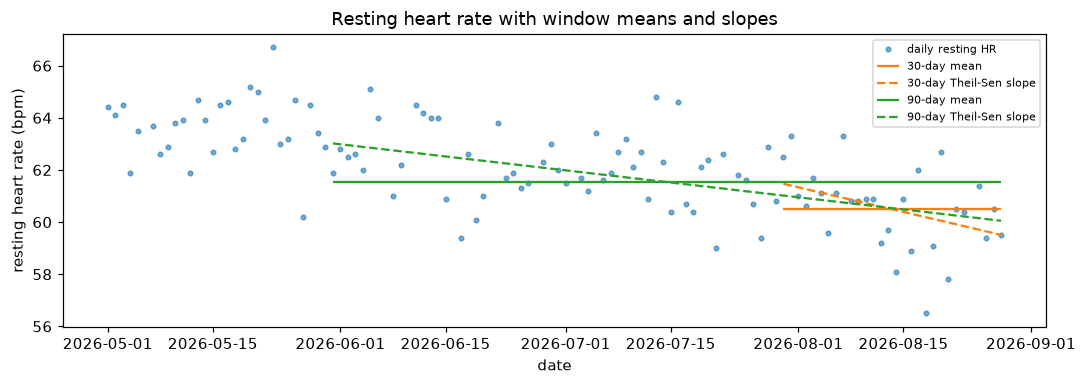

Takeaway: resting HR is falling about 1.0 bpm per month over 90 days.


In [29]:
daily = daily_values(wearables, "resting_heart_rate", window_end)
days_sorted = sorted(daily)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(
    days_sorted,
    [daily[d] for d in days_sorted],
    ".",
    alpha=0.6,
    label="daily resting HR",
)
for span, color in ((30, "tab:orange"), (90, "tab:green")):
    w = windows[f"resting_heart_rate_{span}d"]
    start = window_end - timedelta(days=span - 1)
    ax.hlines(w.mean, start, window_end, colors=color, label=f"{span}-day mean")
    half_rise = w.slope_per_day * (span - 1) / 2
    ax.plot(
        [start, window_end],
        [w.mean - half_rise, w.mean + half_rise],
        color=color,
        ls="--",
        label=f"{span}-day Theil-Sen slope",
    )
ax.set_title("Resting heart rate with window means and slopes")
ax.set_xlabel("date")
ax.set_ylabel("resting heart rate (bpm)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
w90 = windows["resting_heart_rate_90d"]
print(
    f"Takeaway: resting HR is falling about {-w90.slope_per_day * 30:.1f} "
    "bpm per month over 90 days."
)

## 8c. Wearables: the residual model must earn activation

**What and why.** The residual model predicts how far the next lab lands from the stage
below it. It is served only after the gate passes on real consented pairs: enough users,
at least 10% lower pinball loss than both the last lab and the population prior on
held-out users, a bootstrap 95% CI of the gain that excludes zero, and 75-85% coverage.
Real pairs do not exist yet, so we check the gate itself on synthetic data: a set with a
planted wearable signal must pass, and a set with no signal must fail.

In [30]:
def synthetic_pairs(n_users: int, signal: float, seed: int) -> PairSet:
    """Two pairs per user; with signal > 0 the first feature moves the next lab."""
    rng = np.random.default_rng(seed)
    n_rows = 2 * n_users
    features_ = rng.normal(size=(n_rows, 24))
    anchor = np.full(n_rows, 5.8)
    noise = 0.03
    next_lab = anchor * np.exp(signal * features_[:, 0] + rng.normal(0, noise, n_rows))
    spread = np.exp(1.2816 * np.sqrt(signal**2 + noise**2))
    band = np.column_stack([anchor / spread, anchor, anchor * spread])
    return PairSet(
        np.repeat(np.arange(n_users).astype(str), 2),
        features_,
        anchor,
        next_lab,
        {"last_lab": band, "population": band},
    )


gate_rows = []
for label, signal in (("planted signal", 0.08), ("no signal", 0.0)):
    result = gate_residual_model(synthetic_pairs(GATE_MIN_USERS + 100, signal, seed=3))
    gate_rows.append(
        {
            "set": label,
            "passed": result.passed,
            **{k: round(v, 3) for k, v in result.metrics.items()},
            "reasons": "; ".join(result.reasons),
        }
    )
pl.DataFrame(gate_rows)

set,passed,users,model_pinball,coverage_80,last_lab_pinball,improvement_vs_last_lab,population_pinball,improvement_vs_population,ci_lower_gain,reasons
str,bool,f64,f64,f64,f64,f64,f64,f64,f64,str
"""planted signal""",true,300.0,0.048,0.802,0.125,0.615,0.125,0.615,0.071,""""""
"""no signal""",false,300.0,0.044,0.803,0.043,-0.037,0.043,-0.037,-0.002,"""-3.7% better than last_lab; ne…"


**Takeaway.** The gate activates a model that really adds information and refuses one
that does not, so wearable adjustments cannot reach users or PREVENT on noise.

## 8d. Wearables: shadow vs served

**What and why.** With a residual model loaded but not activated, the twin computes the
wearable-adjusted band every night into `ml.shadow_predictions` while still serving the
lab band. Here a model trained on the planted-signal set adjusts the persona's HbA1c;
the plot shows served vs shadow, with a later real lab marked.

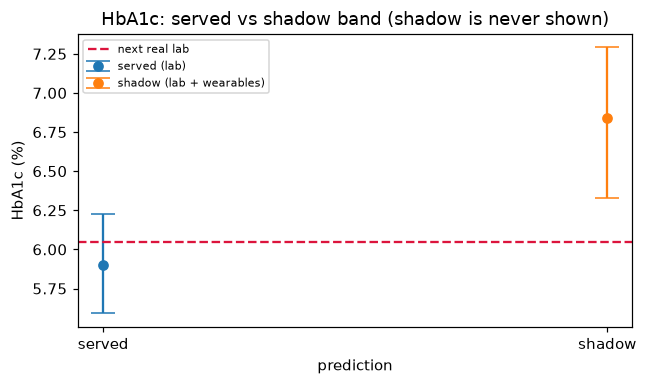

Takeaway: served basis stays 'lab'. The shadow band (6.33-7.29%) comes from a model trained on synthetic features and misses the next lab: exactly the failure shadow mode and the gate keep away from users.


In [31]:
residual = train_residual_model(
    synthetic_pairs(GATE_MIN_USERS + 100, 0.08, seed=4),
    "hba1c",
    "change",
    "demo-residual",
)
shadow_engine = TwinEngine(
    prior=engine.prior,
    registry=registry,
    residual_models={("hba1c", "change"): residual},
    prevent_version=engine.prevent_version,
)
shadow_state = twin_state(
    shadow_engine,
    TwinRequest(
        profile=PERSONA, records=[*lab_records[:5], *wearable_records], as_of=window_end
    ),
)
served = next(p for p in shadow_state.predictions if p.analyte == "hba1c")
shadow = shadow_state.shadow[0]
next_lab_value = 6.05
fig, ax = plt.subplots(figsize=(6, 3.6))
for x, (label, band) in enumerate(
    (
        ("served (lab)", (served.p10, served.p50, served.p90)),
        ("shadow (lab + wearables)", shadow.shadow),
    )
):
    ax.errorbar(
        x,
        band[1],
        yerr=[[band[1] - band[0]], [band[2] - band[1]]],
        fmt="o",
        capsize=8,
        label=label,
    )
ax.axhline(next_lab_value, color="crimson", ls="--", label="next real lab")
ax.set_xticks([0, 1], ["served", "shadow"])
ax.set_title("HbA1c: served vs shadow band (shadow is never shown)")
ax.set_xlabel("prediction")
ax.set_ylabel("HbA1c (%)")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()
shadow_low, shadow_high = shadow.shadow[0], shadow.shadow[2]
print(
    f"Takeaway: served basis stays '{served.basis}'. The "
    f"shadow band ({shadow_low:.2f}-{shadow_high:.2f}%) "
    "comes from a model trained on synthetic features "
    "and misses the next lab: exactly the failure shadow "
    "mode and the gate keep away from users."
)

## 9. Risk score

**What and why.** PREVENT (official AHA R package) runs on measured labs where present
and on the personalized p50 otherwise. `risk_basis` says which; the range is PREVENT at
the p10/p90 ends of every estimated input, so it collapses when everything is measured.

In [32]:
estimated = before.risk
measured = after.risk
pl.DataFrame(
    [
        {
            "input": name,
            "estimated_value": round(estimated.inputs_used[name].value, 1),
            "estimated_source": estimated.inputs_used[name].source,
            "measured_value": round(measured.inputs_used[name].value, 1),
            "measured_source": measured.inputs_used[name].source,
        }
        for name in measured.inputs_used
    ]
)

input,estimated_value,estimated_source,measured_value,measured_source
str,f64,str,f64,str
"""non_hdl""",163.6,"""predicted""",187.0,"""measured"""
"""hdl""",50.2,"""predicted""",41.0,"""measured"""
"""hba1c""",5.4,"""predicted""",5.9,"""measured"""
"""egfr""",91.3,"""predicted""",86.8,"""measured"""
"""sbp""",121.7,"""predicted""",136.0,"""measured"""
"""bmi""",27.5,"""reported""",27.5,"""reported"""
"""diabetes""",0.0,"""reported""",0.0,"""reported"""


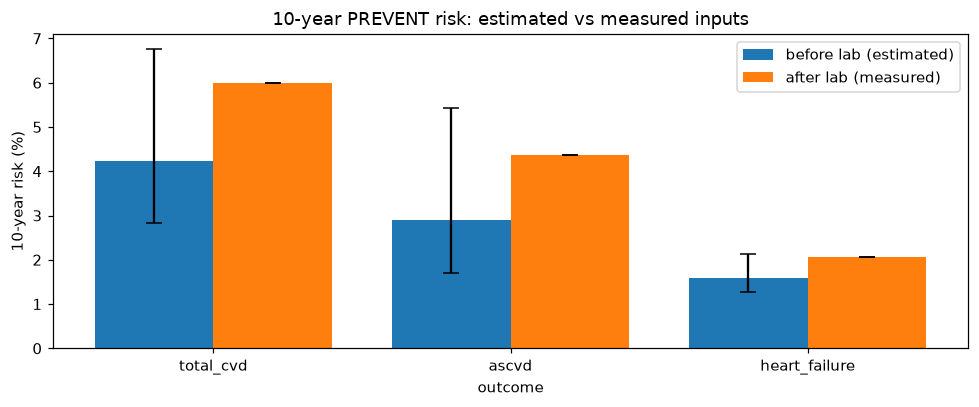

Takeaway: total CVD risk moves from 4.2% (2.8-6.8), estimated, to 6.0% (6.0-6.0), measured, once labs are measured.


In [33]:
fig, ax = plt.subplots(figsize=(9, 3.8))
outcomes = ["total_cvd", "ascvd", "heart_failure"]
positions = np.arange(len(outcomes))
for offset, (label, risk) in (
    (-0.2, (f"before lab ({estimated.risk_basis})", estimated)),
    (0.2, (f"after lab ({measured.risk_basis})", measured)),
):
    ten = {r.outcome: r for r in risk.results if r.horizon_years == 10}
    points = [ten[o].risk_pct for o in outcomes]
    low = [ten[o].risk_pct - ten[o].risk_low for o in outcomes]
    high = [ten[o].risk_high - ten[o].risk_pct for o in outcomes]
    ax.bar(positions + offset, points, 0.4, yerr=[low, high], capsize=5, label=label)
ax.set_xticks(positions, outcomes)
ax.set_title("10-year PREVENT risk: estimated vs measured inputs")
ax.set_xlabel("outcome")
ax.set_ylabel("10-year risk (%)")
ax.legend()
fig.tight_layout()
plt.show()
total_before = next(
    r for r in estimated.results if (r.outcome, r.horizon_years) == ("total_cvd", 10)
)
total_after = next(
    r for r in measured.results if (r.outcome, r.horizon_years) == ("total_cvd", 10)
)


def describe(result) -> str:
    """Risk with its range, for the takeaway."""
    return f"{result.risk_pct:.1f}% ({result.risk_low:.1f}-{result.risk_high:.1f})"


print(
    f"Takeaway: total CVD risk moves from {describe(total_before)}, "
    f"estimated, to {describe(total_after)}, {measured.risk_basis}, "
    "once labs are measured."
)

## 10. End-to-end persona through the API

**What and why.** The same persona calls the real `/v1/twin/state` endpoint twice: at
onboarding (profile only), then after uploading the lab file. The second response is
printed in full, exactly as the backend receives it.

In [34]:
from app import app

api_profile = {**PERSONA, "sex": "Male", "race_eth": "Non-Hispanic White"}
with TestClient(app) as client:
    onboarding = client.post(
        "/v1/twin/state", json={"profile": api_profile, "as_of": "2026-05-01"}
    ).json()
    after_upload = client.post(
        "/v1/twin/state",
        json={
            "user_id": "persona-1",
            "profile": api_profile,
            "records": lab_records,
            "as_of": "2026-05-04",
        },
    ).json()
print(
    "Onboarding:",
    {p["analyte"]: p["basis"] for p in onboarding["predictions"]},
    "| risk_basis:",
    onboarding["risk"]["risk_basis"],
)
print(
    "After upload:",
    {p["analyte"]: p["basis"] for p in after_upload["predictions"]},
    "| risk_basis:",
    after_upload["risk"]["risk_basis"],
)
after_upload_short = {
    **after_upload,
    "wearable_windows": f"<{len(after_upload['wearable_windows'])} windows>",
}
print(orjson.dumps(after_upload_short, option=orjson.OPT_INDENT_2).decode())

2026-11-04 06:55:55,598 - app - INFO - Loaded quantile model version=20261104T1154Z from /Users/khanhpham/Documents/KhanhWorld/MeSquare/MeSquareMLEngine/.claude/worktrees/cardio-digital-twin-personalization-bc7c43/artifacts/quantile


2026-11-04 06:55:55,622 - src.components.record_ingestion - WARNING - Rejected record 691d5f69-8e63-5193-b501-78d163402b71 (HDL): unit 'g/L' is not supported for hdl


Onboarding: {'non_hdl': 'population', 'hdl': 'population', 'hba1c': 'population', 'egfr': 'population', 'sbp': 'population'} | risk_basis: estimated
After upload: {'non_hdl': 'lab', 'hdl': 'lab', 'hba1c': 'lab', 'egfr': 'lab', 'sbp': 'lab'} | risk_basis: measured
{
  "as_of": "2026-05-04",
  "predictions": [
    {
      "analyte": "non_hdl",
      "basis": "lab",
      "basis_label": "Based on your May 4 lab",
      "p10": 164.74461477847183,
      "p50": 187.0,
      "p90": 212.26186996778003,
      "unit": "mg/dL",
      "as_of": "2026-05-04",
      "source_lab_id": "7fc19c93-c0a5-5d85-aa0d-8e0535645476",
      "lab_measured_at": "2026-05-04",
      "change": null
    },
    {
      "analyte": "hdl",
      "basis": "lab",
      "basis_label": "Based on your May 4 lab",
      "p10": 36.44816157067157,
      "p50": 41.0,
      "p90": 46.12029599190089,
      "unit": "mg/dL",
      "as_of": "2026-05-04",
      "source_lab_id": "c71b15fc-9d69-58b6-b13a-6774f696074f",
      "lab_measured_

**Takeaway.** Onboarding gives population bands and an estimated risk for everyone.
After one upload, the lab-anchored analytes carry `source_lab_id`, the bad record is
listed in `rejected_records`, risk is computed from measured inputs where available
(`risk_basis`), and `model_versions` plus `input_hash` make the response traceable and
replayable.